<a href="https://colab.research.google.com/github/bhakti0720/ViT/blob/main/Vision_Transformer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
#import library
import torch
import torch.nn as nn
import torchvision # for data
import torchvision.transforms as transforms  #for data transformation
import torch.utils.data as dataloader        #for baches foramtion

In [15]:
#Transform data which in PIL to tensor format
transformation_opr = transforms.Compose([transforms.ToTensor()])

In [16]:
#import dataset
train_dataset = torchvision.datasets.MNIST(root = './data', train=True, download=True, transform=transformation_opr)
validation_data = torchvision.datasets.MNIST(root='/data', train=False, download=True, transform=transformation_opr)

In [17]:
#define variable(hyperparameters)
num_classes = 10    # 10 numders
batch_size = 64     # no. of imgae per batch
num_channels = 1    # no of color channels
img_size = 28     # no. of pixel along h & w (28x28)
patch_size = 7    # no. of pixel along h & w in each path
num_patches = (img_size // patch_size) **2     # no. patches in image (//) this convert float value in int
print(num_patches)
emb_dim = 64      #vector size for each patch
attention_head = 4        #no. of heads in MHA
transforms_blocks = 4
mlp_hidden_nodes = 128    # 2x of the emb_dim
learning_rate = 0.001
epochs = 5                #how many times we want to pass the training dataset to get more accuracy

16


In [18]:
#define dataset batches
train_loader = dataloader.DataLoader(train_dataset, batch_size = batch_size, shuffle=True)
validation_loader = dataloader.DataLoader(validation_data, batch_size = batch_size, shuffle=True)

1.   Patch Embedding
2.   Transformer encoder
3.   MLP_head
4.   Vision transformer class

In [19]:
#Part 1 : patch embedding
import torch
import torch.nn as nn

class PatchEmbedding(nn.Module):
  def __init__(self):
    super().__init__()
    #conv_layer = nn.Conv2d(in_channels, out_channels, kernel_size, stried)
    self.patch_emb = nn.Conv2d(num_channels, emb_dim, kernel_size=patch_size, stride=patch_size)

  def forward(self, x):
    x =  self.patch_emb(x)
    x = x.flatten(2)
    x = x.transpose(1,2)
    return x

    #calss token & position emb

In [25]:
#Part 2 : transformer Encoder
class TransformerEncoder(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer_norm1 = nn.LayerNorm(emb_dim)
    self.layer_norm2 = nn.LayerNorm(emb_dim)
    self.multihead_attention = nn.MultiheadAttention(emb_dim, attention_head,batch_first=True)
    self.mlp = nn.Sequential(
        nn.Linear(emb_dim, mlp_hidden_nodes),
        nn.GELU(),
        nn.Linear(mlp_hidden_nodes, emb_dim)
    )

  def forward(self, x):
    residual1 = x
    x = self.layer_norm1(x)
    x = self.multihead_attention(x, x, x)[0]
    x = x + residual1

    residual2 = x
    x = self.layer_norm2(x)
    x = self.mlp(x)
    x = x + residual2
    return x

In [26]:
# part 3 MIP head
class MLP_head(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer_norm1 = nn.LayerNorm(emb_dim)
    self.mlp_head = nn.Linear(emb_dim, num_classes)

  def forward(self, x):
    x = self.layer_norm1(x)
    #x = x[:, 0]    this take only 1st emb token
    x = self.mlp_head(x)
    return x

In [27]:
# part 4 ViT block
class vision_transformer(nn.Module):
  def __init__(self):
    super().__init__()
    self.patch_embedding = PatchEmbedding()
    self.mlp_head = MLP_head()
    self.cls_token = nn.Parameter(torch.rand(1, 1, emb_dim))
    self.pos_emb = nn.Parameter(torch.rand(1, num_patches + 1, emb_dim))
    self.transformer_blocks = nn.Sequential(
        *[TransformerEncoder() for _ in range(transforms_blocks)]
    )

  def forward(self, x):
    x = self.patch_embedding(x)
    cls_token = self.cls_token.expand(x.shape[0], -1, -1)
    x = torch.cat((cls_token, x), dim=1)
    x = x + self.pos_emb
    x = self.transformer_blocks(x)
    x = x[:, 0]
    x = self.mlp_head(x)
    return x

In [28]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = vision_transformer().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
criterion = nn.CrossEntropyLoss()

In [29]:
# Training loop
for epoch in range(epochs):
    model.train()

    total_loss = 0
    correct_epoch = 0
    total_epoch = 0

    print(f"\nEpoch {epoch + 1}/{epochs}")
    print("Training...")

    for batch_idx, (data, target) in enumerate(train_loader):
        data, target = data.to(device), target.to(device)

        # 1. Reset gradients
        optimizer.zero_grad()

        # 2. Forward pass
        output = model(data)

        # 3. Calculate loss
        loss = criterion(output, target)

        # 4. Backward pass
        loss.backward()

        # 5. Update weights
        optimizer.step()

        # Accumulate loss
        total_loss += loss.item()

        # Calculate predictions
        preds = output.argmax(dim=1)

        # Count correct predictions
        correct_epoch += (preds == target).sum().item()
        total_epoch += target.size(0)

        # Print progress every 100 batches
        if batch_idx % 100 == 0:
            accuracy = 100.0 * correct_epoch / total_epoch

            print(
                f"Batch {batch_idx}/{len(train_loader)} | "
                f"Loss: {loss.item():.4f} | "
                f"Accuracy: {accuracy:.2f}%"
            )

    # Epoch-level metrics
    avg_loss = total_loss / len(train_loader)
    epoch_accuracy = 100.0 * correct_epoch / total_epoch

    print(f"Epoch {epoch + 1} Summary:")
    print(f"Average Loss: {avg_loss:.4f}")
    print(f"Training Accuracy: {epoch_accuracy:.2f}%")


Epoch 1/5
Training...
Batch 0/938 | Loss: 2.4865 | Accuracy: 6.25%
Batch 100/938 | Loss: 0.7310 | Accuracy: 55.99%
Batch 200/938 | Loss: 0.2431 | Accuracy: 72.01%
Batch 300/938 | Loss: 0.2334 | Accuracy: 78.30%
Batch 400/938 | Loss: 0.1763 | Accuracy: 81.94%
Batch 500/938 | Loss: 0.1336 | Accuracy: 84.36%
Batch 600/938 | Loss: 0.1036 | Accuracy: 86.06%
Batch 700/938 | Loss: 0.0838 | Accuracy: 87.32%
Batch 800/938 | Loss: 0.1395 | Accuracy: 88.30%
Batch 900/938 | Loss: 0.2277 | Accuracy: 89.02%
Epoch 1 Summary:
Average Loss: 0.3419
Training Accuracy: 89.28%

Epoch 2/5
Training...
Batch 0/938 | Loss: 0.2237 | Accuracy: 92.19%
Batch 100/938 | Loss: 0.0827 | Accuracy: 96.57%
Batch 200/938 | Loss: 0.1187 | Accuracy: 96.39%
Batch 300/938 | Loss: 0.1277 | Accuracy: 96.46%
Batch 400/938 | Loss: 0.2248 | Accuracy: 96.45%
Batch 500/938 | Loss: 0.1539 | Accuracy: 96.39%
Batch 600/938 | Loss: 0.0588 | Accuracy: 96.42%
Batch 700/938 | Loss: 0.1599 | Accuracy: 96.45%
Batch 800/938 | Loss: 0.1728 | 

In [30]:
# Validation loop
model.eval()
val_loss = 0
val_correct = 0
val_total = 0

with torch.no_grad():
    for data, target in validation_loader:
        data, target = data.to(device), target.to(device)
        output = model(data)
        val_loss += criterion(output, target).item()
        val_correct += (output.argmax(dim=1) == target).sum().item()
        val_total += target.size(0)

print(f"Validation Loss: {val_loss / len(validation_loader):.4f}")
print(f"Validation Accuracy: {100.0 * val_correct / val_total:.2f}%")


Validation Loss: 0.0755
Validation Accuracy: 97.87%


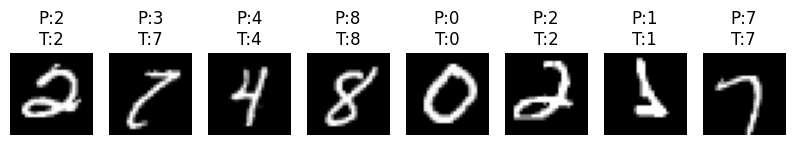

In [31]:
# Predict on a few validation images
import matplotlib.pyplot as plt

data, target = next(iter(validation_loader))
with torch.no_grad():
    preds = model(data.to(device)).argmax(dim=1).cpu()

plt.figure(figsize=(10, 2))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(data[i].squeeze(), cmap='gray')
    plt.title(f"P:{preds[i].item()}\nT:{target[i].item()}")
    plt.axis('off')
plt.show()
